<a href="https://colab.research.google.com/github/kvikaee/deep-learning/blob/main/%D0%93%D0%9E_%D0%9B%D0%A03_%D0%9A%D0%BE%D1%88%D1%83%D1%80%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

В этой лабораторной работе вы будете использовать рекуррентные нейронные сети.

In [ ]:
import os
import re
import glob
import sys
import time
import random
import subprocess
import importlib.util
import warnings

warnings.filterwarnings('ignore')

# устанавливаем kagglehub, если библиотека отсутствует
if importlib.util.find_spec('kagglehub') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Embedding,
    Bidirectional,
    LSTM,
    GRU,
    SpatialDropout1D,
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from IPython.display import display

# фиксируем random seed для воспроизводимости
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


https://www.kaggle.com/datasets/shayanfazeli/heartbeat - набор данных ЭКГ. Используйте мультиклассовый датасет.
https://www.kaggle.com/datasets/datafiniti/consumer-reviews-of-amazon-products/data - отзывы клиентов Амазона. В качестве лейблов используйте оценки клиентов.

Для начала - задача классификации ЭКГ. Импортируйте датасет, подготовьте выборку, постройте и обучите модель, протестируйте её и в виде гистограмм проиллюстрируйте, в каких классах чаще ошибается нейронная сеть. Также для каждого класса постройте отдельную гистограмму, содержащую ложно классифицированные данные по разным классам.

Using Colab cache for faster access to the 'heartbeat' dataset.
Размер обучающего датасета: (87554, 187)
Размер тестового датасета: (21892, 187)

Количество объектов по классам:
0    72471
1     2223
2     5788
3      641
4     6431
Name: count, dtype: int64

Веса классов: {0: 0.24162337662337663, 1: 7.879301217575437, 2: 3.0252032520325205, 3: 27.310091743119266, 4: 2.7230150018294914}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 187, 128)       │        25,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 187, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        31,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,317 (239.52 KB)

 Trainable params: 61,317 (239.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
291/291 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - accuracy: 0.3515 - loss: 1.1651 - val_accuracy: 0.3303 - val_loss: 1.2689 - learning_rate: 0.0010
Epoch 2/15
291/291 ━━━━━━━━━━━━━━━━━━━━ 13s 45ms/step - accuracy: 0.5030 - loss: 0.7651 - val_accuracy: 0.6431 - val_loss: 0.8386 - learning_rate: 0.0010
Epoch 3/15
291/291 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.6373 - loss: 0.6251 - val_accuracy: 0.6754 - val_loss: 0.8007 - learning_rate: 0.0010
Epoch 4/15
291/291 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.6881 - loss: 0.5582 - val_accuracy: 0.6806 - val_loss: 0.8003 - learning_rate: 0.0010
Epoch 5/15
291/291 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.7225 - loss: 0.5184 - val_accuracy: 0.6921 - val_loss: 0.7475 - learning_rate: 0.0010
Epoch 6/15
291/291 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.7534 - loss: 0.4735 - val_accuracy: 0.7256 - val_loss: 0.6552 - learning_rate: 0.0010
Epoch 7/15
291/291 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.7636 - l

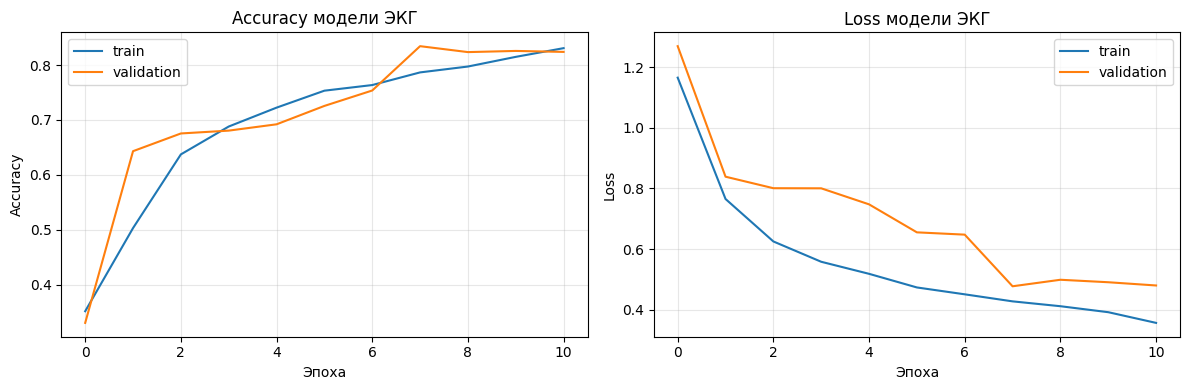

In [ ]:
# скачиваем мультиклассовый датасет ЭКГ
heartbeat_path = kagglehub.dataset_download('shayanfazeli/heartbeat')
heartbeat_files = sorted(glob.glob(os.path.join(heartbeat_path, '*.csv')))


train_file = next(file for file in heartbeat_files if 'mitbih_train' in os.path.basename(file).lower())
test_file = next(file for file in heartbeat_files if 'mitbih_test' in os.path.basename(file).lower())

train_df = pd.read_csv(train_file, header=None)
test_df = pd.read_csv(test_file, header=None)

# последний столбец содержит номер класса
X = train_df.iloc[:, :-1].to_numpy(dtype=np.float32)
y = train_df.iloc[:, -1].to_numpy(dtype=np.int32)

X_test = test_df.iloc[:, :-1].to_numpy(dtype=np.float32)
y_test = test_df.iloc[:, -1].to_numpy(dtype=np.int32)

class_names = {
    0: 'N',
    1: 'S',
    2: 'V',
    3: 'F',
    4: 'Q',
}

print('Размер обучающего датасета:', X.shape)
print('Размер тестового датасета:', X_test.shape)
print('\nКоличество объектов по классам:')
print(pd.Series(y).value_counts().sort_index())

# выделяем validation отдельно с сохранением долей классов
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

# для RNN нужен третий размер: (объекты, временные отсчёты, признаки)
X_train_rnn = X_train[..., np.newaxis]
X_val_rnn = X_val[..., np.newaxis]
X_test_rnn = X_test[..., np.newaxis]

# из-за сильного дисбаланса классов задаём веса классов
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)
class_weights = {int(cls): float(weight) for cls, weight in zip(classes, weights)}

print('\nВеса классов:', class_weights)

model_ecg = Sequential([
    Input(shape=(X_train_rnn.shape[1], 1)),
    Bidirectional(GRU(64, return_sequences=True)),
    Dropout(0.25),
    Bidirectional(GRU(32)),
    Dense(64, activation='relu'),
    Dropout(0.30),
    Dense(len(classes), activation='softmax')
])

model_ecg.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_ecg.summary()

callbacks_ecg = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        restore_best_weights=True,
        mode='max'
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-5
    )
]

start = time.perf_counter()

history_ecg = model_ecg.fit(
    X_train_rnn,
    y_train,
    validation_data=(X_val_rnn, y_val),
    epochs=15,
    batch_size=256,
    class_weight=class_weights,
    callbacks=callbacks_ecg,
    verbose=1
)

ecg_train_time = time.perf_counter() - start

test_loss_ecg, test_acc_ecg = model_ecg.evaluate(
    X_test_rnn,
    y_test,
    verbose=0
)

print(f'\nВремя обучения: {ecg_train_time:.1f} с')
print(f'Test accuracy: {test_acc_ecg:.4f}')

# графики процесса обучения
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_ecg.history['accuracy'], label='train')
plt.plot(history_ecg.history['val_accuracy'], label='validation')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.title('Accuracy модели ЭКГ')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_ecg.history['loss'], label='train')
plt.plot(history_ecg.history['val_loss'], label='validation')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.title('Loss модели ЭКГ')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


В обучающей выборке 87 554 объекта, в тестовой - 21 892. Классы сильно несбалансированы: класс N значительно преобладает, а класс F встречается реже всего.

Для компенсации дисбаланса были рассчитаны веса классов. Наибольший вес получил редкий класс F, а наименьший - наиболее многочисленный класс N.

Модель состоит из двух двунаправленных рекуррентных слоёв, Dropout и полносвязных слоёв. Выходной слой содержит 5 нейронов - по одному для каждого класса ЭКГ.

В процессе обучения accuracy постепенно увеличивается, а loss уменьшается как на обучающей, так и на валидационной выборке. К концу обучения validation accuracy достигает примерно 83%.

На тестовой выборке модель достигла точности 82,43%, что показывает достаточно хорошую способность классифицировать ранее не встречавшиеся сигналы.

Обучение проходит стабильно: accuracy растёт, а loss снижается. В конце появляется небольшое расхождение между train и validation loss, что может указывать на начало переобучения, но оно выражено незначительно.

Test accuracy: 0.8243


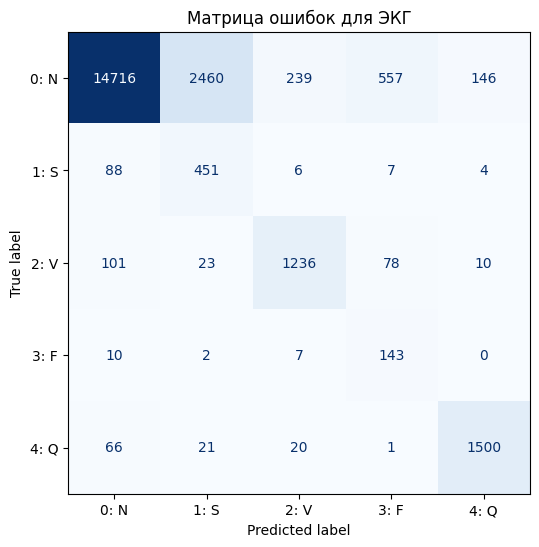

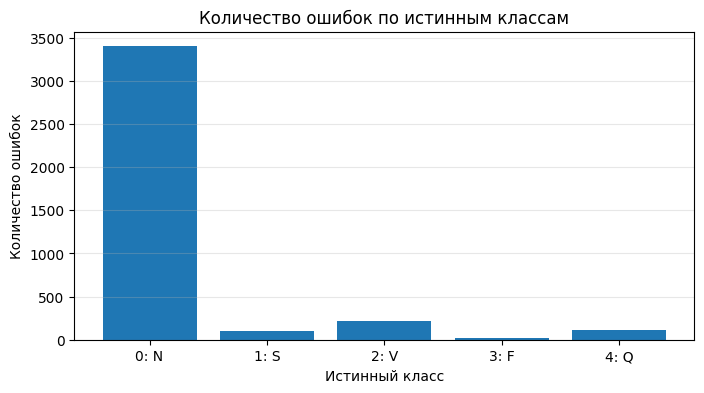

,class,name,objects_in_test,errors,error_rate
0,0,N,18118,3402,0.187769
1,1,S,556,105,0.188849
2,2,V,1448,212,0.146409
3,3,F,162,19,0.117284
4,4,Q,1608,108,0.067164


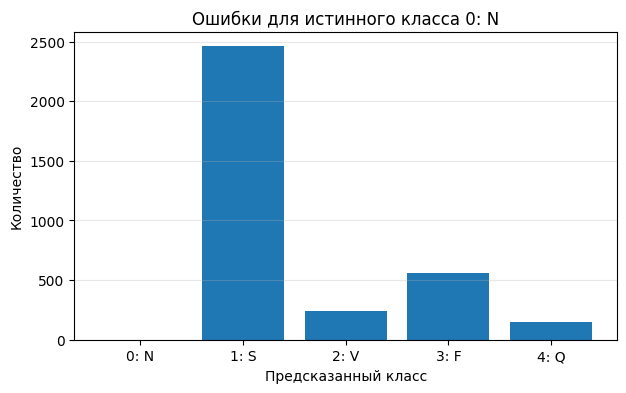

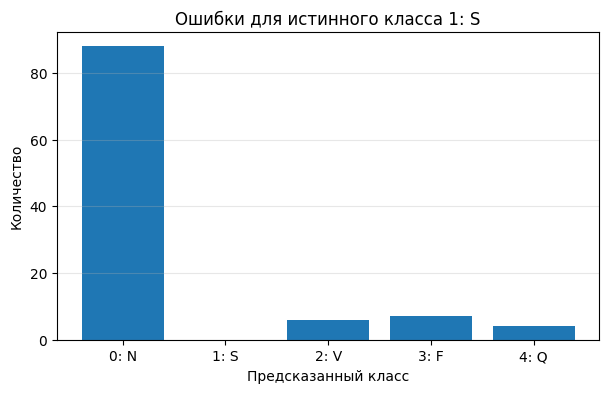

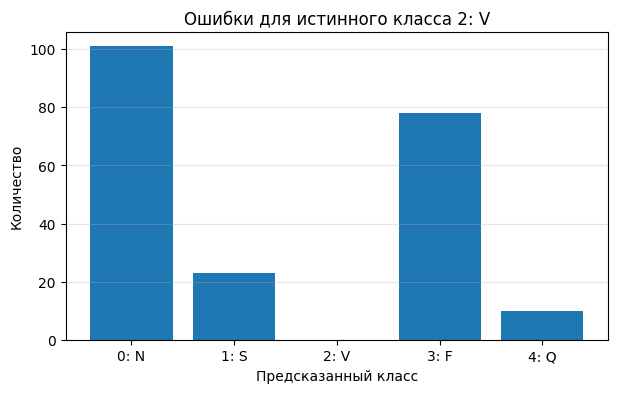

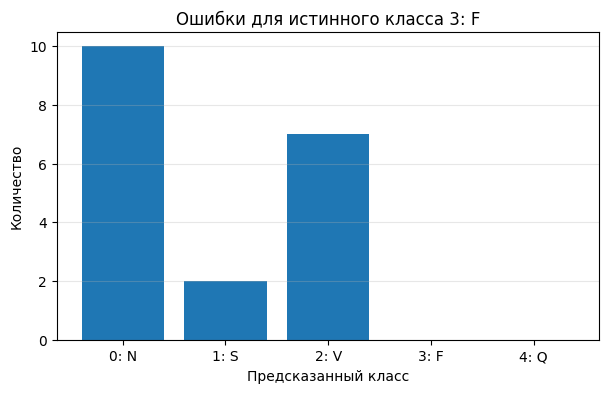

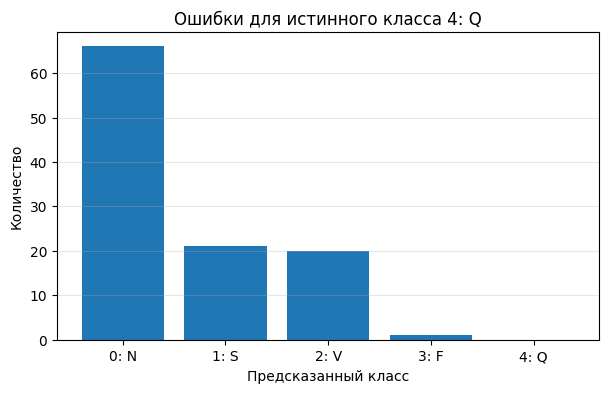

In [ ]:
# получаем предсказания на тестовой выборке
y_prob_ecg = model_ecg.predict(X_test_rnn, verbose=0)
y_pred_ecg = np.argmax(y_prob_ecg, axis=1)

print('Test accuracy:', round(accuracy_score(y_test, y_pred_ecg), 4))

# матрица ошибок
cm = confusion_matrix(y_test, y_pred_ecg, labels=classes)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[f'{i}: {class_names[i]}' for i in classes]
)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Матрица ошибок для ЭКГ')
plt.show()

# общая гистограмма: в каких истинных классах сеть ошибается чаще
wrong_mask = y_pred_ecg != y_test
wrong_true_classes = y_test[wrong_mask]

error_counts = pd.Series(wrong_true_classes).value_counts().reindex(classes, fill_value=0)

plt.figure(figsize=(8, 4))
plt.bar(
    [f'{i}: {class_names[i]}' for i in classes],
    error_counts.values
)
plt.xlabel('Истинный класс')
plt.ylabel('Количество ошибок')
plt.title('Количество ошибок по истинным классам')
plt.grid(axis='y', alpha=0.3)
plt.show()

error_table = pd.DataFrame({
    'class': classes,
    'name': [class_names[i] for i in classes],
    'objects_in_test': [np.sum(y_test == i) for i in classes],
    'errors': [error_counts.loc[i] for i in classes],
})
error_table['error_rate'] = error_table['errors'] / error_table['objects_in_test']

display(error_table)

# отдельная гистограмма для каждого истинного класса
for true_class in classes:
    mask = (y_test == true_class) & (y_pred_ecg != true_class)
    wrong_predictions = y_pred_ecg[mask]

    counts = pd.Series(wrong_predictions).value_counts().reindex(classes, fill_value=0)
    counts.loc[true_class] = 0

    plt.figure(figsize=(7, 4))
    plt.bar(
        [f'{i}: {class_names[i]}' for i in classes],
        counts.values
    )
    plt.xlabel('Предсказанный класс')
    plt.ylabel('Количество')
    plt.title(
        f'Ошибки для истинного класса {true_class}: '
        f'{class_names[true_class]}'
    )
    plt.grid(axis='y', alpha=0.3)
    plt.show()


Большинство объектов всех пяти классов располагается на главной диагонали, то есть классифицируется правильно. Наиболее заметная ошибка - объекты класса N иногда принимаются за класс S.

Наибольшее абсолютное количество ошибок наблюдается для класса N, однако это связано прежде всего с тем, что он значительно превосходит остальные классы по количеству объектов.

По относительной доле ошибок классы N и S имеют около 19% ошибок, V - около 15%, F - около 12%, а класс Q распознаётся лучше остальных - ошибка составляет примерно 7%.

Класс N чаще всего ошибочно определяется как S. Класс S чаще путается с N, класс V - с N и F, класс F - с N и V, а класс Q чаще всего ошибочно относится к N.

В задаче обработки текста в качестве входных данных используйте отзывы клиентов, в качестве выходных - их оценки. Получите точность не ниже 90%. Текст необходимо подготовить. Также подготовьте второй датасет, но к нему примените лемматизацию (например, из nltk) текста. При прочих равных параметрах сравните результаты модели, обученной с помощью обычного словаря и с помощью лемматизированного.

In [ ]:
# скачиваем датасет с отзывами Amazon
amazon_path = kagglehub.dataset_download(
    'datafiniti/consumer-reviews-of-amazon-products'
)

amazon_files = sorted(
    glob.glob(os.path.join(amazon_path, '**', '*.csv'), recursive=True)
)


# выбираем CSV, в котором есть и текст отзыва, и рейтинг
required_text_columns = ['reviews.text', 'review.text', 'text']
required_rating_columns = ['reviews.rating', 'review.rating', 'rating']

candidate_files = []

for file in amazon_files:
    try:
        header = pd.read_csv(file, nrows=3, low_memory=False)
        text_col = next(
            (col for col in required_text_columns if col in header.columns),
            None
        )
        rating_col = next(
            (col for col in required_rating_columns if col in header.columns),
            None
        )

        if text_col is not None and rating_col is not None:
            candidate_files.append((file, text_col, rating_col))
    except Exception:
        pass

if not candidate_files:
    raise FileNotFoundError(
        'Не найден CSV с колонками текста отзыва и рейтинга.'
    )

# берём самый большой подходящий файл
amazon_file, text_col, rating_col = max(
    candidate_files,
    key=lambda item: os.path.getsize(item[0])
)

amazon_df = pd.read_csv(amazon_file, low_memory=False)

print('\nИспользуется файл:', os.path.basename(amazon_file))
print('Текстовая колонка:', text_col)
print('Колонка рейтинга:', rating_col)

# если есть заголовок отзыва, добавляем его к основному тексту
title_col = next(
    (
        col for col in ['reviews.title', 'review.title', 'title']
        if col in amazon_df.columns
    ),
    None
)

if title_col is not None:
    review_text = (
        amazon_df[title_col].fillna('').astype(str)
        + ' '
        + amazon_df[text_col].fillna('').astype(str)
    )
else:
    review_text = amazon_df[text_col].fillna('').astype(str)

ratings = pd.to_numeric(amazon_df[rating_col], errors='coerce')

text_df = pd.DataFrame({
    'text': review_text,
    'rating': ratings
})

# оставляем стандартные оценки 1–5 и непустые отзывы
text_df = text_df[
    text_df['rating'].isin([1, 2, 3, 4, 5])
].copy()

text_df['rating'] = text_df['rating'].astype(int)
text_df['text'] = text_df['text'].astype(str).str.strip()
text_df = text_df[text_df['text'].str.len() > 0].reset_index(drop=True)

def clean_text(text):
    text = text.lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r"[^a-z\s']", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

text_df['clean_text'] = text_df['text'].map(clean_text)
text_df = text_df[text_df['clean_text'].str.len() > 0].reset_index(drop=True)

print('\nРазмер датасета:', text_df.shape)
print('\nРаспределение оценок:')
print(text_df['rating'].value_counts().sort_index())

# превращаем оценки 1–5 в номера классов 0–4
rating_values = sorted(text_df['rating'].unique().tolist())
rating_to_id = {rating: i for i, rating in enumerate(rating_values)}
id_to_rating = {i: rating for rating, i in rating_to_id.items()}

labels = text_df['rating'].map(rating_to_id).to_numpy(dtype=np.int32)
indices = np.arange(len(text_df))

# сначала отделяем test, затем validation
idx_train_val, idx_test = train_test_split(
    indices,
    test_size=0.15,
    random_state=SEED,
    stratify=labels
)

idx_train, idx_val = train_test_split(
    idx_train_val,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=labels[idx_train_val]
)

y_text_train = labels[idx_train]
y_text_val = labels[idx_val]
y_text_test = labels[idx_test]

NUM_WORDS = 40000
MAX_LEN = 180
EMBEDDING_DIM = 128
TEXT_EPOCHS = 15
TEXT_BATCH_SIZE = 128

def prepare_text_sequences(texts, train_idx, val_idx, test_idx):
    tokenizer = Tokenizer(
        num_words=NUM_WORDS,
        oov_token='<OOV>'
    )
    tokenizer.fit_on_texts(texts.iloc[train_idx])

    train_seq = tokenizer.texts_to_sequences(texts.iloc[train_idx])
    val_seq = tokenizer.texts_to_sequences(texts.iloc[val_idx])
    test_seq = tokenizer.texts_to_sequences(texts.iloc[test_idx])

    X_train_seq = pad_sequences(
        train_seq,
        maxlen=MAX_LEN,
        padding='post',
        truncating='post'
    )
    X_val_seq = pad_sequences(
        val_seq,
        maxlen=MAX_LEN,
        padding='post',
        truncating='post'
    )
    X_test_seq = pad_sequences(
        test_seq,
        maxlen=MAX_LEN,
        padding='post',
        truncating='post'
    )

    return tokenizer, X_train_seq, X_val_seq, X_test_seq

def build_text_model(n_classes):
    model = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(
            input_dim=NUM_WORDS,
            output_dim=EMBEDDING_DIM,
            mask_zero=True
        ),
        SpatialDropout1D(0.20),
        Bidirectional(
            LSTM(
                96,
                return_sequences=True,
                dropout=0.15
            )
        ),
        Bidirectional(
            LSTM(
                48,
                dropout=0.15
            )
        ),
        Dense(96, activation='relu'),
        Dropout(0.30),
        Dense(n_classes, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

def make_text_callbacks():
    return [
        EarlyStopping(
            monitor='val_accuracy',
            patience=3,
            restore_best_weights=True,
            mode='max'
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=1e-5
        )
    ]

# обычная подготовка текста
tokenizer_raw, X_raw_train, X_raw_val, X_raw_test = prepare_text_sequences(
    text_df['clean_text'],
    idx_train,
    idx_val,
    idx_test
)

tf.keras.backend.clear_session()
model_raw = build_text_model(len(rating_values))

print('\nМодель для обычного текста:')
model_raw.summary()

start = time.perf_counter()

history_raw = model_raw.fit(
    X_raw_train,
    y_text_train,
    validation_data=(X_raw_val, y_text_val),
    epochs=TEXT_EPOCHS,
    batch_size=TEXT_BATCH_SIZE,
    callbacks=make_text_callbacks(),
    verbose=1
)

raw_train_time = time.perf_counter() - start
raw_test_loss, raw_test_acc = model_raw.evaluate(
    X_raw_test,
    y_text_test,
    verbose=0
)

print(f'\nОбычный текст - время обучения: {raw_train_time:.1f} с')
print(f'Обычный текст - test accuracy: {raw_test_acc:.4f}')


Using Colab cache for faster access to the 'consumer-reviews-of-amazon-products' dataset.

Используется файл: Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products_May19.csv
Текстовая колонка: reviews.text
Колонка рейтинга: reviews.rating

Размер датасета: (28332, 3)

Распределение оценок:
rating
1      965
2      616
3     1206
4     5648
5    19897
Name: count, dtype: int64

Модель для обычного текста:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 180, 128)       │     5,120,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 180, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 180, 192)       │       172,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 96)             │        92,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 96)             │         9,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           485 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,395,141 (20.58 MB)

 Trainable params: 5,395,141 (20.58 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - accuracy: 0.7254 - loss: 0.7507 - val_accuracy: 0.7861 - val_loss: 0.5413 - learning_rate: 0.0010
Epoch 2/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.7997 - loss: 0.5051 - val_accuracy: 0.8047 - val_loss: 0.5099 - learning_rate: 0.0010
Epoch 3/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.8343 - loss: 0.4281 - val_accuracy: 0.8113 - val_loss: 0.5012 - learning_rate: 0.0010
Epoch 4/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.8594 - loss: 0.3709 - val_accuracy: 0.8141 - val_loss: 0.5109 - learning_rate: 0.0010
Epoch 5/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.8817 - loss: 0.3175 - val_accuracy: 0.8320 - val_loss: 0.5062 - learning_rate: 0.0010
Epoch 6/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.9086 - loss: 0.2571 - val_accuracy: 0.8231 - val_loss: 0.5199 - learning_rate: 5.0000e-04
Epoch 7/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9261 - los

После подготовки в датасете осталось 28 332 отзыва. Распределение оценок также сильно несбалансировано: преобладают отзывы с оценкой 5, тогда как оценок 1 и 2 значительно меньше.

Текст преобразуется в векторные представления с помощью Embedding, после чего обрабатывается двумя двунаправленными рекуррентными слоями. Итоговый слой выполняет классификацию на пять оценок от 1 до 5.

Accuracy на обучающей выборке достигает примерно 96%, тогда как validation accuracy стабилизируется около 85%. При этом validation loss после нескольких эпох начинает увеличиваться, поэтому наблюдаются признаки переобучения.

Accuracy на обучающей выборке достигает примерно 96%, тогда как validation accuracy стабилизируется около 85%. При этом validation loss после нескольких эпох начинает увеличиваться, поэтому наблюдаются признаки переобучения.

Модель на обычном тексте показала точность 85,76%, что стало лучшим результатом в эксперименте.

In [ ]:
# подготавливаем второй вариант датасета с лемматизацией
import nltk
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    words = text.split()

    # последовательно пробуем формы глагола, существительного и прилагательного
    lemmas = []
    for word in words:
        lemma = lemmatizer.lemmatize(word, pos='v')
        lemma = lemmatizer.lemmatize(lemma, pos='n')
        lemma = lemmatizer.lemmatize(lemma, pos='a')
        lemmas.append(lemma)

    return ' '.join(lemmas)

start = time.perf_counter()
text_df['lemmatized_text'] = text_df['clean_text'].map(lemmatize_text)
lemmatization_time = time.perf_counter() - start

print(f'Время лемматизации: {lemmatization_time:.1f} с')
print('\nПример до лемматизации:')
print(text_df.loc[0, 'clean_text'])
print('\nПример после лемматизации:')
print(text_df.loc[0, 'lemmatized_text'])

# split, длина последовательности, словарь и архитектура остаются теми же
tokenizer_lemma, X_lemma_train, X_lemma_val, X_lemma_test = prepare_text_sequences(
    text_df['lemmatized_text'],
    idx_train,
    idx_val,
    idx_test
)

tf.keras.backend.clear_session()
model_lemma = build_text_model(len(rating_values))

print('\nМодель для лемматизированного текста:')
model_lemma.summary()

start = time.perf_counter()

history_lemma = model_lemma.fit(
    X_lemma_train,
    y_text_train,
    validation_data=(X_lemma_val, y_text_val),
    epochs=TEXT_EPOCHS,
    batch_size=TEXT_BATCH_SIZE,
    callbacks=make_text_callbacks(),
    verbose=1
)

lemma_train_time = time.perf_counter() - start
lemma_test_loss, lemma_test_acc = model_lemma.evaluate(
    X_lemma_test,
    y_text_test,
    verbose=0
)

print(f'\nЛемматизированный текст - время обучения: {lemma_train_time:.1f} с')
print(f'Лемматизированный текст - test accuracy: {lemma_test_acc:.4f}')


Время лемматизации: 10.3 с

Пример до лемматизации:
of them and one of the item is bad quality is missing backup spring so i have i order of them and one of the item is bad quality is missing backup spring so i have to put a pcs of aluminum to make the battery work

Пример после лемматизации:
of them and one of the item be bad quality be miss backup spring so i have i order of them and one of the item be bad quality be miss backup spring so i have to put a pc of aluminum to make the battery work

Модель для лемматизированного текста:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 180, 128)       │     5,120,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 180, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 180, 192)       │       172,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 96)             │        92,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 96)             │         9,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           485 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,395,141 (20.58 MB)

 Trainable params: 5,395,141 (20.58 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.7228 - loss: 0.7563 - val_accuracy: 0.7769 - val_loss: 0.5700 - learning_rate: 0.0010
Epoch 2/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.7906 - loss: 0.5304 - val_accuracy: 0.7885 - val_loss: 0.5257 - learning_rate: 0.0010
Epoch 3/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step - accuracy: 0.8210 - loss: 0.4557 - val_accuracy: 0.8026 - val_loss: 0.5155 - learning_rate: 0.0010
Epoch 4/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.8435 - loss: 0.4049 - val_accuracy: 0.8078 - val_loss: 0.5150 - learning_rate: 0.0010
Epoch 5/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.8618 - loss: 0.3607 - val_accuracy: 0.8155 - val_loss: 0.5264 - learning_rate: 0.0010
Epoch 6/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - accuracy: 0.8848 - loss: 0.3149 - val_accuracy: 0.8108 - val_loss: 0.5427 - learning_rate: 0.0010
Epoch 7/15
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.9070 - loss: 0

Лемматизация приводит слова к базовой форме, например is/missing преобразуются в be/miss. Это уменьшает вариативность словоформ, но одновременно может удалять часть информации о естественной форме высказывания.

Модель также хорошо обучается, однако её validation accuracy немного ниже, чем у модели на обычном тексте. Аналогично наблюдаются признаки переобучения: train accuracy продолжает расти, когда качество на validation почти перестаёт улучшаться.

,Подготовка текста,Лучшая val accuracy,Test accuracy,"Время обучения, с"
0,Обычная,0.8496,0.8576,99.9306
1,Лемматизация,0.8480,0.8461,110.9912


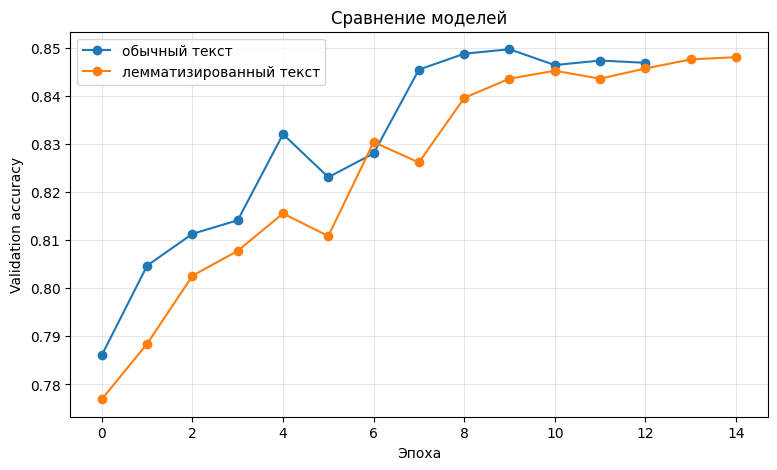

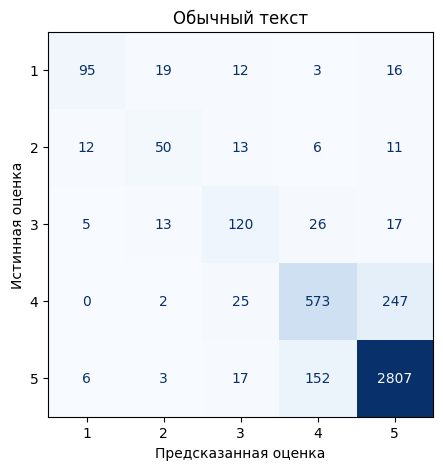

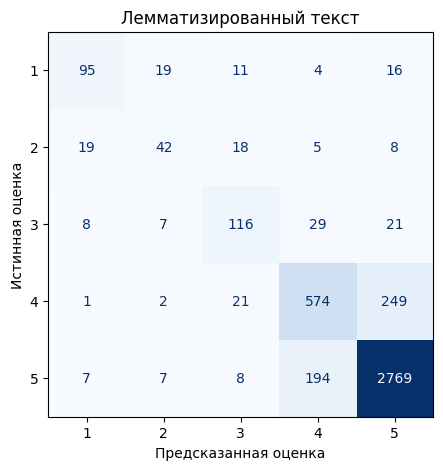

Лучший результат на test: Обычная, accuracy = 0.8576
Лемматизация снизила test accuracy на 0.0115.
На данном разбиении test accuracy ниже 90%. Для точного предсказания всех пяти оценок это может потребовать больше данных, эпох или более крупной модели.


In [ ]:
# сравниваем модели при одинаковых параметрах
comparison = pd.DataFrame([
    {
        'Подготовка текста': 'Обычная',
        'Лучшая val accuracy': max(history_raw.history['val_accuracy']),
        'Test accuracy': raw_test_acc,
        'Время обучения, с': raw_train_time,
    },
    {
        'Подготовка текста': 'Лемматизация',
        'Лучшая val accuracy': max(history_lemma.history['val_accuracy']),
        'Test accuracy': lemma_test_acc,
        'Время обучения, с': lemma_train_time,
    },
])

display(comparison.round(4))

plt.figure(figsize=(9, 5))
plt.plot(
    history_raw.history['val_accuracy'],
    marker='o',
    label='обычный текст'
)
plt.plot(
    history_lemma.history['val_accuracy'],
    marker='o',
    label='лемматизированный текст'
)
plt.xlabel('Эпоха')
plt.ylabel('Validation accuracy')
plt.title('Сравнение моделей')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# матрицы ошибок на тестовой выборке
raw_pred = np.argmax(
    model_raw.predict(X_raw_test, verbose=0),
    axis=1
)
lemma_pred = np.argmax(
    model_lemma.predict(X_lemma_test, verbose=0),
    axis=1
)

for title, pred in [
    ('Обычный текст', raw_pred),
    ('Лемматизированный текст', lemma_pred),
]:
    cm_text = confusion_matrix(
        y_text_test,
        pred,
        labels=np.arange(len(rating_values))
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_text,
        display_labels=rating_values
    )
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    plt.xlabel('Предсказанная оценка')
    plt.ylabel('Истинная оценка')
    plt.title(title)
    plt.show()

best_name = comparison.loc[
    comparison['Test accuracy'].idxmax(),
    'Подготовка текста'
]
best_acc = comparison['Test accuracy'].max()

print(
    f'Лучший результат на test: {best_name}, '
    f'accuracy = {best_acc:.4f}'
)

difference = lemma_test_acc - raw_test_acc

if difference > 0:
    print(
        f'Лемматизация повысила test accuracy на '
        f'{difference:.4f}.'
    )
elif difference < 0:
    print(
        f'Лемматизация снизила test accuracy на '
        f'{abs(difference):.4f}.'

    )


Лучше всего модель распознаёт отзывы с оценкой 5 - правильно классифицировано 2807 из 2985 отзывов. Основная ошибка для оценки 4 - предсказание 5 звёзд, что показывает сложность различения близких положительных оценок.

После лемматизации ухудшилось распознавание некоторых классов, особенно оценки 2 и частично оценки 5. Для оценок 3 и 4 существенного улучшения не произошло.

В ходе лабораторной работы были исследованы рекуррентные нейронные сети для двух задач многоклассовой классификации: распознавания типов ЭКГ и определения оценки отзыва Amazon по тексту.

Для классификации ЭКГ использовалась модель на основе двух двунаправленных LSTM-слоёв с Dropout и полносвязными слоями. Для борьбы с сильным дисбалансом классов применялись веса классов. При этом модель распознавала все пять классов, хотя качество по отдельным классам различалось из-за их неравномерного представления в выборке.

Во второй части решалась задача классификации отзывов Amazon по оценкам от 1 до 5. Наиболее удачным оказался гибридный подход. Текст отзыва сначала проходил через TextVectorization, Embedding и два двунаправленных GRU-слоя. Параллельно рассчитывались дополнительные признаки тональности, после чего текстовое представление и числовые признаки объединялись перед финальной классификацией.

В дополнительные признаки были включены оценки тональности VADER, количество положительных и отрицательных слов, отрицания, усилители, слова с более умеренной оценкой, устойчивые положительные и отрицательные выражения, количество восклицательных знаков и длина отзыва. Отдельно учитывались конструкции противопоставления but, however, although, though, yet, а также изменение тональности до и после такого противопоставления. Это позволяло учитывать случаи вроде положительного отзыва с последующим замечанием: например, great product, but ....

Лучший результат для обычного текста составил примерно 85% accuracy. При использовании лемматизации результат оказался немного хуже - примерно на 1.15 процентного пункта. Поэтому в данной задаче сохранение исходных словоформ оказалось полезнее. Вероятно, при лемматизации частично терялась информация о конкретных языковых конструкциях, которая уже могла быть извлечена самой GRU-моделью.

Требуемую точность 90% получить не удалось. Основная причина заключается в особенностях самих данных. Классы сильно несбалансированы: отзывов с оценкой 5 значительно больше, чем отзывов с низкими оценками. Кроме того, соседние оценки часто имеют очень похожий текст. Особенно заметна путаница между 4 и 5 звёздами: оба класса обычно содержат положительные отзывы, а различие часто заключается лишь в небольшом замечании или конструкции вида but ....

Для повышения точности были проверены несколько подходов. Увеличивались размер словаря, длина текстовой последовательности и размер GRU-модели, однако существенного прироста это не дало. Применение class_weight позволило уделять больше внимания редким классам, но снизило общую accuracy примерно до 65%. Также была протестирована предобученная модель DistilBERT, которая дала результат порядка 74%, то есть оказалась хуже гибридной GRU-модели. Дополнительно предпринималась попытка отдельно улучшить распознавание классов 4 и 5, однако это также снизило итоговое качество примерно до 72%.

Таким образом, наиболее эффективным решением для данного датасета оказалась именно гибридная Bidirectional GRU-модель с дополнительными признаками тональности. Она показала лучший результат среди протестированных вариантов, однако дальнейшее повышение до 90% ограничивается прежде всего сильным дисбалансом классов и семантической близостью соседних оценок, а не только сложностью нейронной сети.